# Lab 14: Recommendation System Using Collaborative Filtering

**Aim:** Implement UBCF, IBCF, Matrix Factorization and SVD, then visualize and compare recommendations.

Import the libraries used for calculations, similarity, matrix factorization and plots.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD

Create a small sample dataset of movie ratings given by users.

In [2]:
ratings_data = [
    [1, 'Movie_A', 5], [1, 'Movie_B', 4], [1, 'Movie_C', 1], [1, 'Movie_D', 2],
    [2, 'Movie_A', 4], [2, 'Movie_B', 5], [2, 'Movie_C', 1], [2, 'Movie_E', 3],
    [3, 'Movie_A', 1], [3, 'Movie_C', 5], [3, 'Movie_D', 4], [3, 'Movie_E', 4],
    [4, 'Movie_B', 2], [4, 'Movie_C', 4], [4, 'Movie_D', 5], [4, 'Movie_F', 4],
    [5, 'Movie_A', 5], [5, 'Movie_B', 3], [5, 'Movie_E', 4], [5, 'Movie_F', 2],
    [6, 'Movie_C', 4], [6, 'Movie_D', 5], [6, 'Movie_E', 3], [6, 'Movie_F', 5]
]

ratings = pd.DataFrame(ratings_data, columns=['User', 'Item', 'Rating'])
display(ratings.head(10))
print("Number of ratings:", len(ratings))

,User,Item,Rating
0,1,Movie_A,5
1,1,Movie_B,4
2,1,Movie_C,1
3,1,Movie_D,2
4,2,Movie_A,4
5,2,Movie_B,5
6,2,Movie_C,1
7,2,Movie_E,3
8,3,Movie_A,1
9,3,Movie_C,5


Number of ratings: 24


Convert the ratings into a user-item matrix. Missing ratings are represented by 0.

In [3]:
user_item = ratings.pivot_table(index='User', columns='Item', values='Rating').fillna(0)
display(user_item)

Item,Movie_A,Movie_B,Movie_C,Movie_D,Movie_E,Movie_F
User,,,,,,
1,5.0,4.0,1.0,2.0,0.0,0.0
2,4.0,5.0,1.0,0.0,3.0,0.0
3,1.0,0.0,5.0,4.0,4.0,0.0
4,0.0,2.0,4.0,5.0,0.0,4.0
5,5.0,3.0,0.0,0.0,4.0,2.0
6,0.0,0.0,4.0,5.0,3.0,5.0


Visualize the user-item rating matrix.

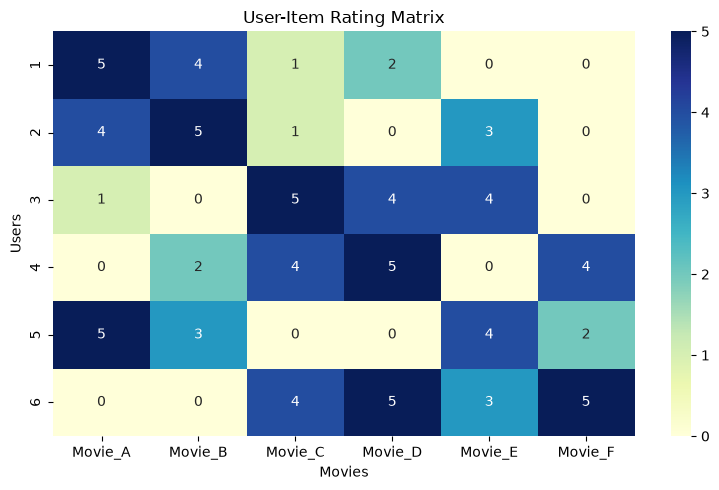

In [4]:
plt.figure(figsize=(8, 5))
sns.heatmap(user_item, annot=True, cmap='YlGnBu', vmin=0, vmax=5)
plt.title("User-Item Rating Matrix")
plt.xlabel("Movies")
plt.ylabel("Users")
plt.tight_layout()
plt.show()

## 1. User-Based Collaborative Filtering (UBCF)\nFind users with similar rating patterns and use their ratings to predict missing ratings.

In [5]:
user_similarity = cosine_similarity(user_item)
user_similarity_df = pd.DataFrame(
    user_similarity, index=user_item.index, columns=user_item.index
)

display(user_similarity_df.round(2))

# Predict ratings using similarity-weighted ratings from other users
user_means = user_item.replace(0, np.nan).mean(axis=1)
centered = user_item.sub(user_means, axis=0).fillna(0)
ubcf_scores = pd.DataFrame(
    user_similarity @ centered.values,
    index=user_item.index,
    columns=user_item.columns
)
ubcf_predictions = ubcf_scores.div(
    np.maximum(np.abs(user_similarity).sum(axis=1), 1e-9), axis=0
).add(user_means, axis=0).clip(1, 5)

target_user = 1
unrated = user_item.loc[target_user] == 0
ubcf_recommendations = ubcf_predictions.loc[target_user, unrated].sort_values(ascending=False)

print("UBCF recommendations for User", target_user)
display(ubcf_recommendations.to_frame("Predicted Rating"))

User,1,2,3,4,5,6
User,,,,,,
1,1.00,0.85,0.35,0.42,0.74,0.24
2,0.85,1.00,0.39,0.25,0.90,0.21
3,0.35,0.39,1.00,0.67,0.38,0.79
4,0.42,0.25,0.67,1.00,0.24,0.90
5,0.74,0.90,0.38,0.24,1.00,0.35
6,0.24,0.21,0.79,0.90,0.35,1.00


UBCF recommendations for User 1


,Predicted Rating
Item,
Movie_E,1.740867
Movie_F,1.000000


## 2. Item-Based Collaborative Filtering (IBCF)\nFind movies with similar rating patterns and use a user's existing ratings to predict unrated movies.

In [6]:
item_similarity = cosine_similarity(user_item.T)
item_similarity_df = pd.DataFrame(
    item_similarity, index=user_item.columns, columns=user_item.columns
)
display(item_similarity_df.round(2))

# Similarity-weighted prediction for each user's unrated movies
ibcf_predictions = pd.DataFrame(
    user_item.values @ item_similarity,
    index=user_item.index,
    columns=user_item.columns
)
similarity_weights = (user_item.values != 0) @ np.abs(item_similarity)
ibcf_predictions = ibcf_predictions.div(
    np.maximum(similarity_weights, 1e-9)
).clip(1, 5)

ibcf_recommendations = ibcf_predictions.loc[target_user, unrated].sort_values(ascending=False)
print("IBCF recommendations for User", target_user)
display(ibcf_recommendations.to_frame("Predicted Rating"))

Item,Movie_A,Movie_B,Movie_C,Movie_D,Movie_E,Movie_F
Item,,,,,,
Movie_A,1.00,0.91,0.22,0.20,0.62,0.18
Movie_B,0.91,1.00,0.30,0.29,0.52,0.28
Movie_C,0.22,0.30,1.00,0.96,0.64,0.70
Movie_D,0.20,0.29,0.96,1.00,0.52,0.80
Movie_E,0.62,0.52,0.64,0.52,1.00,0.48
Movie_F,0.18,0.28,0.70,0.80,0.48,1.00


IBCF recommendations for User 1


,Predicted Rating
Item,
Movie_E,2.978695
Movie_F,2.211383


Visualize the item similarity matrix.

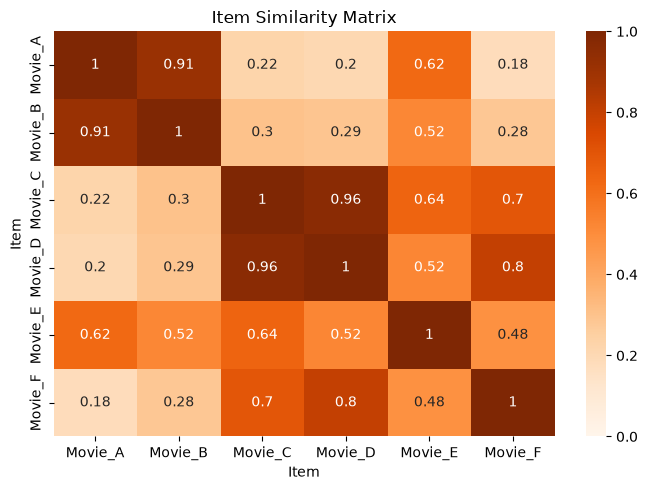

In [7]:
plt.figure(figsize=(7, 5))
sns.heatmap(item_similarity_df, annot=True, cmap='Oranges', vmin=0, vmax=1)
plt.title("Item Similarity Matrix")
plt.tight_layout()
plt.show()

## 3. Matrix Factorization using SVD\nReduce the user-item matrix into latent features, then reconstruct predicted ratings.

In [8]:
n_components = 2
svd = TruncatedSVD(n_components=n_components, random_state=42)
user_factors = svd.fit_transform(user_item)
item_factors = svd.components_

svd_predictions = pd.DataFrame(
    user_factors @ item_factors,
    index=user_item.index,
    columns=user_item.columns
).clip(1, 5)

print("User factor matrix shape:", user_factors.shape)
print("Item factor matrix shape:", item_factors.shape)
print("Explained variance ratio:", round(svd.explained_variance_ratio_.sum(), 3))

svd_recommendations = svd_predictions.loc[target_user, unrated].sort_values(ascending=False)
print("SVD recommendations for User", target_user)
display(svd_recommendations.to_frame("Predicted Rating"))

User factor matrix shape: (6, 2)
Item factor matrix shape: (2, 6)
Explained variance ratio: 0.708
SVD recommendations for User 1


,Predicted Rating
Item,
Movie_E,2.356631
Movie_F,1.000000


## 4. Compare Recommendations\nCompare the top recommendations produced by the three methods.

,UBCF,IBCF,SVD
Item,,,
Movie_E,1.74,2.98,2.36
Movie_F,1.00,2.21,1.00


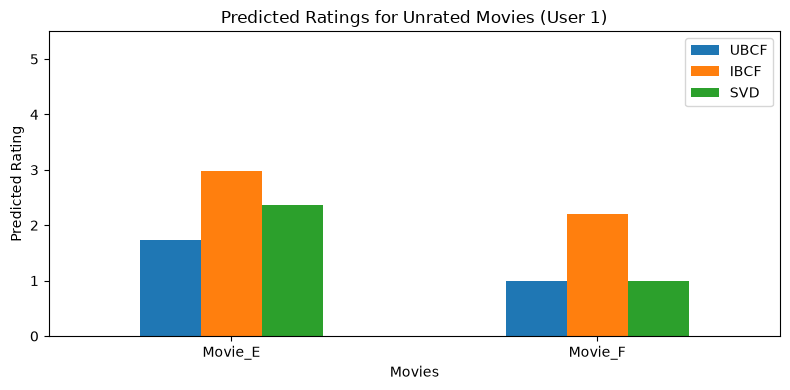

In [9]:
comparison = pd.DataFrame({
    'UBCF': ubcf_predictions.loc[target_user, unrated],
    'IBCF': ibcf_predictions.loc[target_user, unrated],
    'SVD': svd_predictions.loc[target_user, unrated]
})
display(comparison.round(2))

comparison.plot(kind='bar', figsize=(8, 4))
plt.title(f"Predicted Ratings for Unrated Movies (User {target_user})")
plt.ylabel("Predicted Rating")
plt.xlabel("Movies")
plt.ylim(0, 5.5)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Conclusion

UBCF recommends items using similar users, while IBCF uses similar items. Matrix Factorization with SVD discovers latent features to estimate missing ratings. Heatmaps and comparison charts help interpret the recommendations.

## Exercises / Assignments

**1. Add a new user and generate recommendations.**

In [10]:
new_user_ratings = pd.DataFrame(
    [[7, 'Movie_A', 5], [7, 'Movie_C', 2], [7, 'Movie_F', 4]],
    columns=['User', 'Item', 'Rating']
)
ratings_extended = pd.concat([ratings, new_user_ratings], ignore_index=True)
matrix_extended = ratings_extended.pivot_table(
    index='User', columns='Item', values='Rating'
).fillna(0)

print("Updated user-item matrix:")
display(matrix_extended)

# Simple popularity-based fallback for the new user's unrated movies
new_user_unrated = matrix_extended.loc[7] == 0
new_user_recommendations = (
    matrix_extended.drop(index=7).replace(0, np.nan).mean()
    .loc[new_user_unrated]
    .sort_values(ascending=False)
)
print("Recommendations for new User 7:")
display(new_user_recommendations.to_frame("Average Rating"))

Updated user-item matrix:


Item,Movie_A,Movie_B,Movie_C,Movie_D,Movie_E,Movie_F
User,,,,,,
1,5.0,4.0,1.0,2.0,0.0,0.0
2,4.0,5.0,1.0,0.0,3.0,0.0
3,1.0,0.0,5.0,4.0,4.0,0.0
4,0.0,2.0,4.0,5.0,0.0,4.0
5,5.0,3.0,0.0,0.0,4.0,2.0
6,0.0,0.0,4.0,5.0,3.0,5.0
7,5.0,0.0,2.0,0.0,0.0,4.0


Recommendations for new User 7:


,Average Rating
Item,
Movie_D,4.0
Movie_B,3.5
Movie_E,3.5


**2. Compare UBCF and IBCF recommendation results.**

In [11]:
print("UBCF top recommendations:")
display(ubcf_recommendations.head(3).to_frame("Predicted Rating"))

print("IBCF top recommendations:")
display(ibcf_recommendations.head(3).to_frame("Predicted Rating"))

UBCF top recommendations:


,Predicted Rating
Item,
Movie_E,1.740867
Movie_F,1.000000


IBCF top recommendations:


,Predicted Rating
Item,
Movie_E,2.978695
Movie_F,2.211383


**3. Change the number of SVD components and observe the effect.**

In [12]:
svd_3 = TruncatedSVD(n_components=3, random_state=42)
user_factors_3 = svd_3.fit_transform(user_item)
predictions_3 = user_factors_3 @ svd_3.components_

print("2 components - explained variance:",
      round(svd.explained_variance_ratio_.sum(), 3))
print("3 components - explained variance:",
      round(svd_3.explained_variance_ratio_.sum(), 3))
print("Prediction matrix shape with 3 components:", predictions_3.shape)

2 components - explained variance: 0.708
3 components - explained variance: 0.865
Prediction matrix shape with 3 components: (6, 6)


**4. Visualize predicted ratings using a heatmap.**

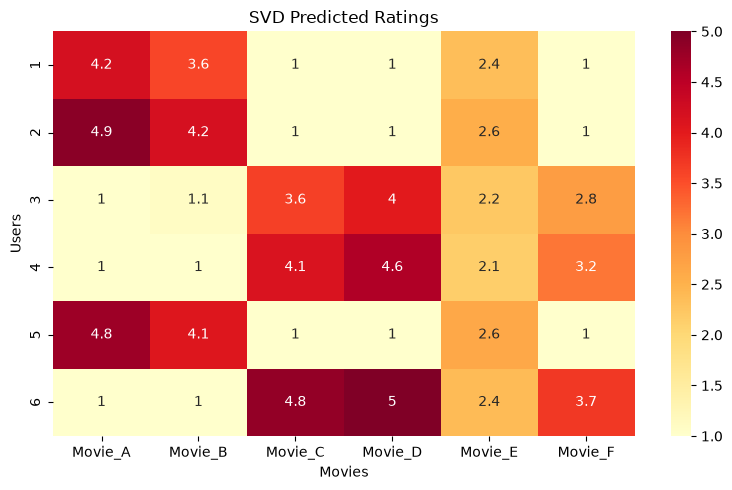

In [13]:
plt.figure(figsize=(8, 5))
sns.heatmap(svd_predictions, annot=True, cmap='YlOrRd', vmin=1, vmax=5)
plt.title("SVD Predicted Ratings")
plt.xlabel("Movies")
plt.ylabel("Users")
plt.tight_layout()
plt.show()

**5. Advantages of collaborative filtering over content-based filtering**

- It uses user rating behaviour rather than requiring detailed item descriptions.
- It can discover unexpected interests from patterns across users.
- It can recommend items with different characteristics if users with similar preferences liked them.

A limitation is the cold-start problem: recommendations are difficult when a new user or item has little interaction data.

**Note:** This is a small demonstration dataset. The predicted ratings are illustrative and are not a formal accuracy evaluation.